En esta actividad se realiza la segmentación de una imagen RGB de una tomografía craneal mediante la optimización de los pesos de los canales rojo (R), verde (G) y azul (B). El propósito es obtener una imagen en escala de grises con mayor contraste para facilitar la identificación y separación de las regiones de interés, principalmente el cráneo y el posible tumor.
Para encontrar la combinación de pesos más adecuada se utiliza el método de optimización SLSQP, estableciendo como restricciones que la suma de los tres coeficientes sea igual a 1 y que cada uno tenga un valor entre 0 y 1.
Después, se comparan los resultados de la segmentación tradicional y la optimizada. Finalmente, se identifican las regiones, se obtienen sus contornos y se calcula el área correspondiente al posible tumor en píxeles.


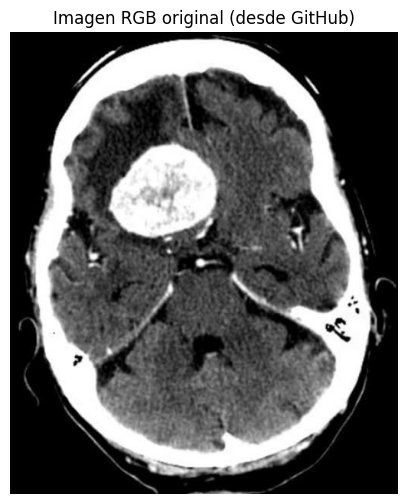

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from scipy.optimize import minimize
from skimage import measure

img_url = "https://raw.githubusercontent.com/dilp90/PDI/main/Imagenes/Te-me_0015.jpg"
img = io.imread(img_url)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis('off')
plt.title('Imagen RGB original (desde GitHub)')
plt.show()

**2) Segmentación sencilla**

Conversión a RGB y optimización de pesos para escala de grises (SLSQP)
Primero, la imagen se convierte al formato RGB y se separa en sus tres canales: rojo, verde y azul. Posteriormente, los valores de cada canal se normalizan entre 0 y 1 para facilitar las operaciones matemáticas.
Después, se establece una función objetivo que busca maximizar la varianza de la imagen en escala de grises. Esto se debe a que una mayor varianza permite obtener una mejor diferenciación entre las zonas claras y oscuras. Como la función minimize() de SciPy está diseñada para minimizar, se utiliza el valor negativo de la varianza para conseguir el efecto contrario.
La optimización se lleva a cabo mediante el método SLSQP, considerando dos condiciones: los pesos deben mantenerse entre 0 y 1 y su suma debe ser igual a 1. De esta manera, se obtienen los coeficientes que permiten generar una imagen en escala de grises con una distribución de intensidades optimizada.
Finalmente, se visualiza la imagen resultante y cada uno de los canales RGB por separado.


R_norm: 0.0 1.0
G_norm: 0.0 1.0
B_norm: 0.0 1.0
Shape imagen: (605, 507, 3)
Tipo de imagen: uint8

📌 Pesos óptimos: [0.33 0.33 0.34]


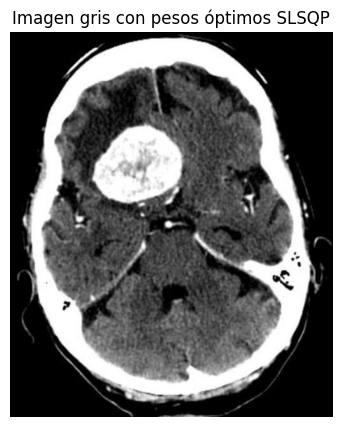

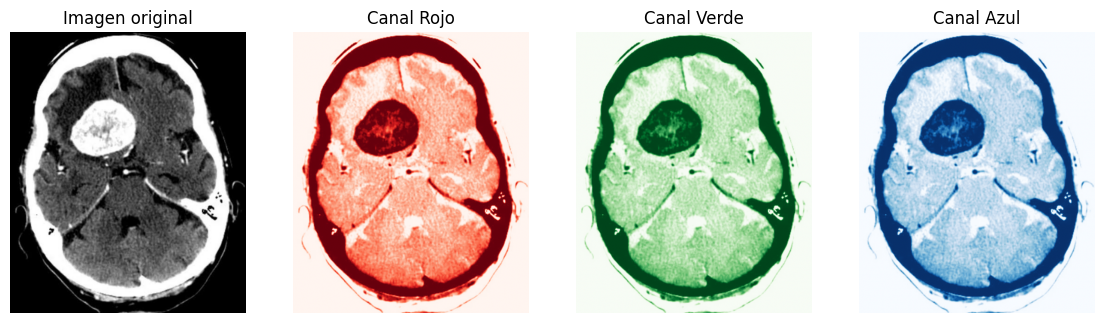

In [4]:
import cv2

# Convertir a RGB (por si viene en BGR)
if img.shape[2] == 3:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
else:
    img_rgb = img

# Separar canales
R = img_rgb[:, :, 0]
G = img_rgb[:, :, 1]
B = img_rgb[:, :, 2]

# Normalizar canales entre 0 y 1
R_norm = R.astype(np.float32) / 255
G_norm = G.astype(np.float32) / 255
B_norm = B.astype(np.float32) / 255

print("R_norm:", R_norm.min(), R_norm.max())
print("G_norm:", G_norm.min(), G_norm.max())
print("B_norm:", B_norm.min(), B_norm.max())
print("Shape imagen:", img_rgb.shape)
print("Tipo de imagen:", img.dtype)

# --------------------------------------------------------
# FUNCION OBJETIVO (maximizar varianza -> minimizar negativo)
# --------------------------------------------------------
def grayscale_variance(weights):
    w_r, w_g, w_b = weights
    gray = w_r * R_norm + w_g * G_norm + w_b * B_norm
    gray_norm = (gray - gray.min()) / (gray.max() - gray.min() + 1e-8)
    return -np.var(gray_norm)

# Restricción: w_r + w_g + w_b = 1
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})

# Límites de cada peso
bounds = [(0, 1), (0, 1), (0, 1)]

# Valor inicial
initial_weights = [0.33, 0.33, 0.34]

# Ejecución SLSQP
result = minimize(grayscale_variance,
                  initial_weights,
                  method='SLSQP',
                  bounds=bounds,
                  constraints=constraints)

optimal_weights = result.x
print("\n📌 Pesos óptimos:", optimal_weights)

# Imagen gris optimizada
wR, wG, wB = optimal_weights
gray_opt = wR*R_norm + wG*G_norm + wB*B_norm
gray_opt = (gray_opt - gray_opt.min()) / (gray_opt.max() - gray_opt.min() + 1e-8)

# Mostrar la imagen resultante
plt.figure(figsize=(5,5))
plt.imshow(gray_opt, cmap='gray')
plt.title("Imagen gris con pesos óptimos SLSQP")
plt.axis('off')
plt.show()

# Mostrar los canales por separado
plt.figure(figsize=(14, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_rgb)
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(R, cmap='Reds')
plt.title('Canal Rojo')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(G, cmap='Greens')
plt.title('Canal Verde')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(B, cmap='Blues')
plt.title('Canal Azul')
plt.axis('off')

plt.show()

Lo convertimos a escalas de grises

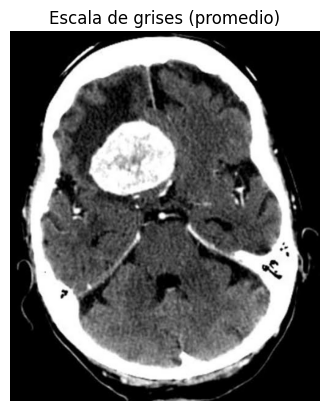

In [ ]:
# Convertir a escala de grises promediando canales
gray_avg = ((R.astype(np.float32) + G + B) / 3).astype(np.uint8)

# Mostrar imagen en escala de grises
plt.imshow(gray_avg, cmap='gray')
plt.title('Escala de grises (promedio)')
plt.axis('off')
plt.show()

**Segmentación sencilla por umbral**

En esta etapa se aplica un método básico de segmentación utilizando un umbral fijo de intensidad. El procedimiento consiste en comparar el valor de cada píxel con el umbral establecido: los píxeles que lo superan se convierten en blancos, mientras que los que tienen un valor menor se representan en negro.

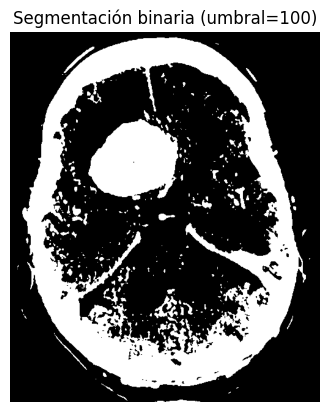

In [9]:
# Umbral para segmentación
umbral = 100
_, segmentada = cv2.threshold(gray_avg, umbral, 255, cv2.THRESH_BINARY)

# Mostrar imagen segmentada
plt.imshow(segmentada, cmap='gray')
plt.title(f'Segmentación binaria (umbral={umbral})')
plt.axis('off')
plt.show()


**3) Segmentación óptima**

Preparación de la imagen

Para comenzar con la segmentación óptima, se carga la imagen desde un repositorio en línea y se verifica que se encuentre en el formato RGB. Posteriormente, se separan sus tres canales de color (R, G y B), ya que sus valores individuales serán necesarios para realizar el proceso de optimización.
Esta separación permite trabajar con cada canal de manera independiente y determinar qué combinación contribuye mejor a resaltar las características de la imagen.


In [5]:
# Asegurar conversión BGR → RGB solo si viene en BGR
if img.shape[2] == 3:
    try:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    except:
        img_rgb = img  # Si ya está en RGB, se deja igual
else:
    img_rgb = img

# Separación de canales
R, G, B = img_rgb[:, :, 0], img_rgb[:, :, 1], img_rgb[:, :, 2]

*Obtención de los pesos óptimos*

En esta parte se calculan los coeficientes que se asignarán a cada canal RGB mediante el método SLSQP. El objetivo es encontrar la combinación que genere una imagen en escala de grises con la mayor varianza posible, buscando mejorar el contraste y facilitar la separación de las diferentes estructuras.
Para realizar este procedimiento:
Se normalizan los valores de los tres canales entre 0 y 1.
Se define una función que calcula la varianza de la imagen en escala de grises.
Se utiliza el método SLSQP para encontrar los pesos que maximizan dicha varianza.
Se establece que los coeficientes deben estar entre 0 y 1 y que su suma debe ser igual a 1.
Al finalizar, se obtienen los pesos óptimos que se utilizarán en la conversión de la imagen a escala de grises.


In [6]:
# Normalizar canales entre 0 y 1
R_norm = R.astype(np.float32) / 255
G_norm = G.astype(np.float32) / 255
B_norm = B.astype(np.float32) / 255

# Función objetivo: varianza negativa (porque minimize() minimiza)
def grayscale_variance(weights):
    w_r, w_g, w_b = weights
    gray = w_r * R_norm + w_g * G_norm + w_b * B_norm
    gray_normalized = (gray - gray.min()) / (gray.max() - gray.min())
    return -np.var(gray_normalized)  # Negativo para maximizar

# Restricción: suma de pesos debe ser 1
constraints = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})

# Límites de cada peso: entre 0 y 1
bounds = [(0, 1), (0, 1), (0, 1)]

# Valor inicial
initial_weights = [0.33, 0.33, 0.34]

# Optimización
result = minimize(grayscale_variance, initial_weights, method='SLSQP',
                  bounds=bounds, constraints=constraints)

optimal_weights = result.x
print("Pesos óptimos:", optimal_weights)

Pesos óptimos: [0.33 0.33 0.34]


**Generación y comparación de imágenes en escala de grises**

Una vez obtenidos los coeficientes óptimos, se combinan los canales R, G y B aplicando el peso correspondiente a cada uno. El resultado es una nueva imagen en escala de grises que busca resaltar las diferencias de intensidad y mejorar el contraste.
Para observar los cambios, se comparan dos imágenes: una obtenida mediante el promedio tradicional de los tres canales y otra generada utilizando los pesos calculados por SLSQP.
Esta comparación permite identificar las diferencias entre ambos métodos y observar cómo la combinación optimizada modifica la distribución de intensidades de la imagen, lo que puede favorecer la identificación de las estructuras que se desean segmentar.


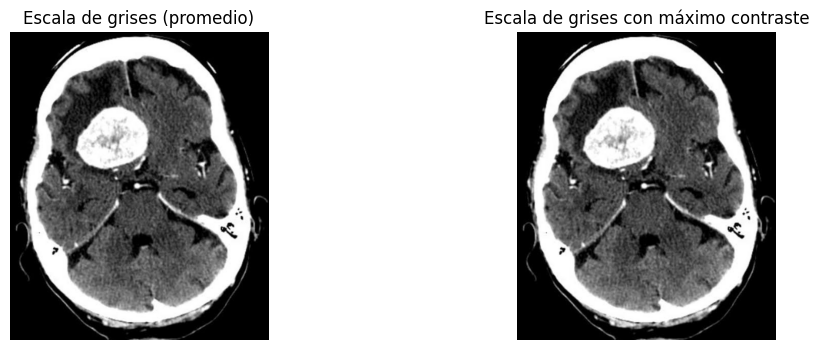

In [8]:
# Calcular gray_avg para asegurar que la variable esté definida
gray_avg = ((R.astype(np.float32) + G + B) / 3).astype(np.uint8)

# Crear imagen en escala de grises con pesos óptimos
gray_optimal = optimal_weights[0] * R_norm + optimal_weights[1] * G_norm + optimal_weights[2] * B_norm
gray_optimal = (gray_optimal * 255).astype(np.uint8)

# Mostrar resultado
# Imagen obtenida de manera directa o sencilla
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(gray_avg, cmap='gray')
plt.title('Escala de grises (promedio)')
plt.axis('off')

# Imagen obtenida de manera óptima
plt.subplot(1, 2, 2)
plt.imshow(gray_optimal, cmap='gray')
plt.title('Escala de grises con máximo contraste')
plt.axis('off')
plt.show()

**Segmentación mediante umbral**

Después de generar ambas imágenes en escala de grises, se aplica el mismo umbral de intensidad a cada una para convertirlas en imágenes binarias.
La primera corresponde a la segmentación tradicional y funciona como punto de comparación, mientras que la segunda utiliza la imagen obtenida mediante la optimización de los canales RGB.
Al observar ambos resultados, es posible analizar cómo influye la modificación del contraste en la separación de las regiones claras y oscuras. Esto permite evaluar cuál de los dos métodos ofrece una representación más adecuada para continuar con el análisis de las estructuras de interés.


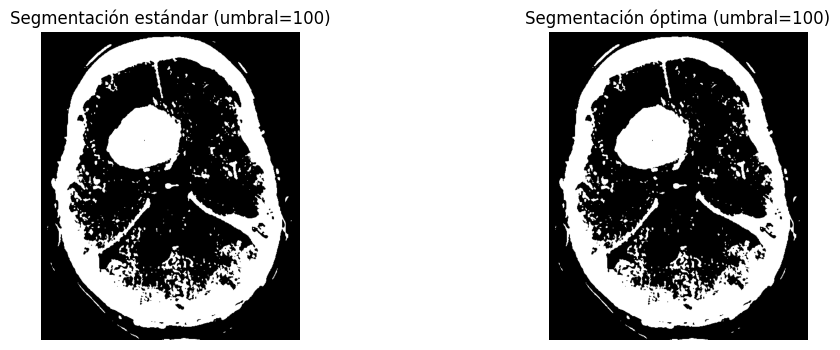

In [ ]:
# Segmentar ambas imágenes con un mismo umbral
umbral = 100
_, seg_standard = cv2.threshold(gray_avg, umbral, 255, cv2.THRESH_BINARY)
_, seg_optimal = cv2.threshold(gray_optimal, umbral, 255, cv2.THRESH_BINARY)

# Mostrar resultado
# Imagen obtenida de manera directa o sencilla
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(seg_standard, cmap='gray')
plt.title(f'Segmentación estándar (umbral={umbral})')
plt.axis('off')

# Imagen obtenida de manera óptima
plt.subplot(1, 2, 2)
plt.imshow(seg_optimal, cmap='gray')
plt.title(f'Segmentación óptima (umbral={umbral})')
plt.axis('off')
plt.show()

**4) Eliminación de ruido y obtención de contornos**

En esta etapa se trabaja con la imagen binaria obtenida mediante la segmentación óptima para identificar las regiones más importantes. Primero, se realiza el etiquetado de los componentes conectados, lo que permite distinguir las diferentes áreas presentes en la imagen.
Posteriormente, las regiones se ordenan de acuerdo con su tamaño y se seleccionan las dos de mayor área para generar máscaras independientes.
A partir de estas máscaras se extraen los contornos y se representan sobre la imagen original para facilitar su visualización:
Rojo: contorno correspondiente al cráneo.
Amarillo: contorno correspondiente a la posible región tumoral.
De esta manera, se obtiene una representación visual que permite observar las regiones identificadas durante el proceso de segmentación.


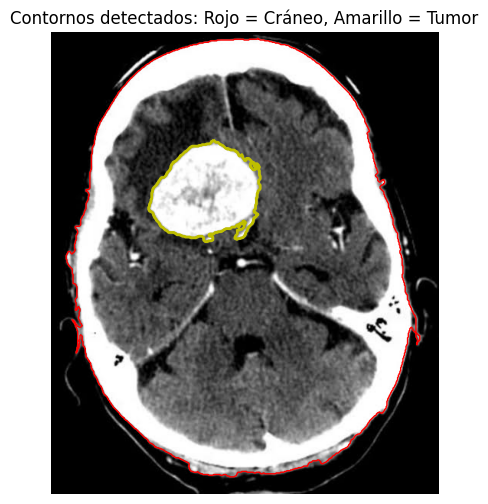

In [ ]:

# -----------------------------------------
# Convertir la segmentación óptima a booleano
# -----------------------------------------
bw = seg_optimal.astype(bool)

# -----------------------------------------
# Limpiar ruido
# -----------------------------------------
bw_clean = bw.copy()

# Etiquetado
label_img = measure.label(bw_clean)
regions = measure.regionprops(label_img)

# -----------------------------------------
# SI NO HAY REGIONES
# -----------------------------------------
if len(regions) == 0:
    print('No se detectaron regiones tras limpiar la segmentación.')
else:
    regions_sorted = sorted(regions, key=lambda r: r.area, reverse=True)
    if len(regions_sorted) >= 2:
        skull_reg = regions_sorted[0]
        tumor_reg = regions_sorted[1]
    else:
        skull_reg = regions_sorted[0]
        tumor_reg = None

    # -----------------------------------------
    # Crear máscaras separadas
    # -----------------------------------------
    skull_mask = (label_img == skull_reg.label)
    tumor_mask = (label_img == tumor_reg.label) if tumor_reg else np.zeros_like(label_img, dtype=bool)

    # -----------------------------------------
    # Función para obtener contornos
    # -----------------------------------------
    def mask_to_contours(mask):
        mask_u8 = (mask.astype(np.uint8) * 255)
        contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        return contours

    skull_cnts = mask_to_contours(skull_mask)
    tumor_cnts = mask_to_contours(tumor_mask)

    # -----------------------------------------
    # Mostrar contornos sobre la imagen original
    # -----------------------------------------
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    ax.imshow(img_rgb)   # tu imagen original en color

    # contornos cráneo → rojo
    for cnt in skull_cnts:
        cnt = cnt.squeeze()
        ax.plot(cnt[:, 0], cnt[:, 1], '-r', linewidth=1)

    # contornos tumor → amarillo
    for cnt in tumor_cnts:
        cnt = cnt.squeeze()
        ax.plot(cnt[:, 0], cnt[:, 1], '-y', linewidth=2)

    ax.set_title('Contornos detectados: Rojo = Cráneo, Amarillo = Tumor')
    ax.axis('off')

    plt.show()


In [ ]:
# Cálculo del área del tumor

if tumor_reg is not None:
    tumor_area_px = tumor_reg.area
    print(f'Área del tumor (en píxeles): {tumor_area_px}')

else:
    print('No se pudo determinar una región como tumor.')

Área del tumor (en píxeles): 13849.0


**5) Cálculo del área del tumor**

Finalmente, se calcula el área de la región identificada como posible tumor utilizando el número de píxeles que ocupa dentro de la imagen segmentada.
El resultado se expresa inicialmente en píxeles cuadrados (px²). Si se conoce la resolución espacial de la imagen, es decir, la equivalencia entre píxeles y milímetros, también es posible convertir esta medida a milímetros cuadrados (mm²), multiplicando el área obtenida por el cuadrado de la escala en mm/píxel.
Este último procedimiento permite cuantificar el tamaño de la región identificada y complementar el análisis realizado durante la segmentación.
